# Week 08 — Lecture 2: X-ray Physics, Spectra, Ionization & Dosimetry

This notebook consolidates the physics behind X-ray / CT image formation that we introduced
conceptually last time, and extends it toward **CT numbers (Hounsfield units)** and **dosimetry**.

**Recap from Lecture 1.** A **radiograph** is a *projection* — the **sum of attenuation** of an
X-ray beam along its path from source to detector through the object. Collecting projections over
many orientations and applying the **inverse Radon transform** yields a **tomographic** CT slice,
i.e. a true cross-section with no influence from neighboring planes.

**This lecture adds:**
1. The discrete serial-block attenuation model (aggregate $\mu$ of several tissues).
2. Discrete (photon-count) vs continuous (intensity) forms of the Beer–Lambert law.
3. The **polyenergetic** X-ray spectrum: photon flux, mean photon energy, tungsten characteristic peaks.
4. **Beam hardening** in spectral terms.
5. Ionization mechanisms: **photoelectric effect** ($\propto Z, E$) and **Compton scattering** ($\propto$ electron density).
6. Energy dependence of $\mu$ and soft-vs-hard tissue separability (the “white mouse / bony mouse”).
7. **Half-value layer** $\text{HVL}=0.693/\mu$.
8. **Linear** ($\mu$, cm$^{-1}$) vs **mass** ($\mu/\rho$, cm$^2$/g) attenuation coefficients.
9. **Hounsfield units** (CT number, referenced near 50 keV), bright-vs-dark, and contrast agents.
10. Preview of the three reconstruction methods (Radon, algebraic, filtered back-projection).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
plt.rcParams["figure.dpi"] = 110

## 1. Discrete serial-block attenuation model

Along one beam path there is usually **not** a single tissue but a *series* of blocks (soft tissue,
bone, fat, …), each with its own $\mu_i$ over thickness $\Delta x$. What the detector measures is the
**aggregate** attenuation:
$$I = I_0\,\exp\!\Big(-\sum_i \mu_i\,\Delta x\Big).$$
The number of blocks we choose to divide the path into sets how many unknown $\mu_i$ we must later
**solve for** during reconstruction.

aggregate line-integral  sum(mu*dx) = 1.40
transmitted fraction     I/I0       = 0.2466


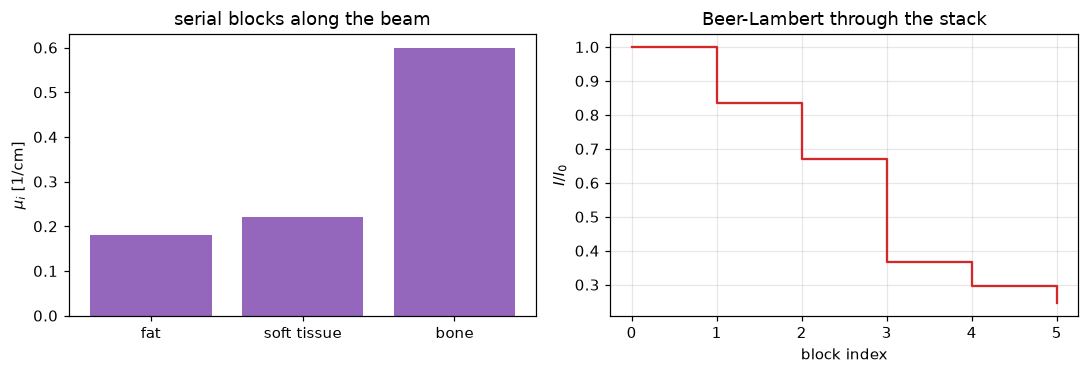

In [2]:
# Five serial tissue blocks along one beam path
labels = ["fat", "soft tissue", "bone", "soft tissue", "fat"]
mu = np.array([0.18, 0.22, 0.60, 0.22, 0.18])   # linear attenuation [1/cm] at a fixed energy
dx = 1.0                                          # each block 1 cm thick

I0 = 1.0
I_path = I0 * np.exp(-np.cumsum(mu) * dx)          # intensity after each block
total = mu.sum() * dx                              # the projection value (line integral of mu)
print(f"aggregate line-integral  sum(mu*dx) = {total:.2f}")
print(f"transmitted fraction     I/I0       = {I_path[-1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].bar(labels, mu, color="tab:purple"); ax[0].set_ylabel(r"$\mu_i$ [1/cm]")
ax[0].set_title("serial blocks along the beam")
ax[1].step(range(len(mu) + 1), np.r_[I0, I_path], where="post", color="tab:red")
ax[1].set_xlabel("block index"); ax[1].set_ylabel("$I/I_0$")
ax[1].set_title("Beer-Lambert through the stack"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 2. Beer–Lambert: discrete (photons) vs continuous (intensity)

The same law has two equivalent views that share the **same $\mu$**:

- **Continuous (intensity):** $\;I = I_0\,e^{-\mu x}$.
- **Discrete (particle count):** a slab of thickness $\Delta x$ removes a fraction of the $n$ incoming
  photons, $\;n \to n - \Delta n$, with $\Delta n = \mu\, n\, \Delta x$.

Because photons are discrete *packets of energy*, a Monte-Carlo count of surviving photons converges
to the smooth exponential.

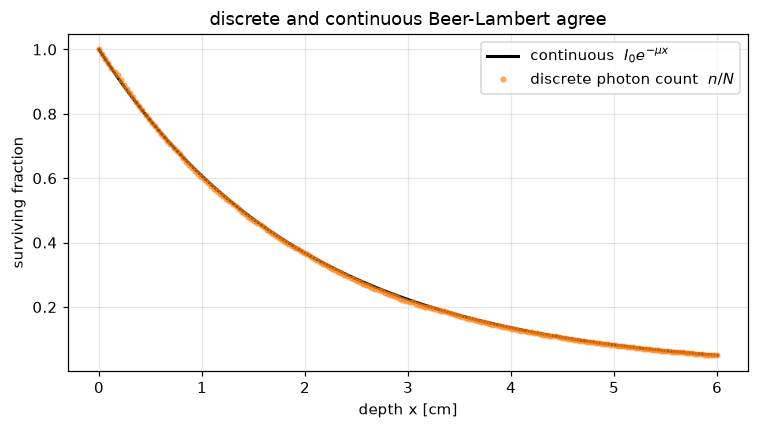

In [3]:
mu0 = 0.5                      # [1/cm]
x = np.linspace(0, 6, 200)     # depth [cm]
I_cont = np.exp(-mu0 * x)      # continuous Beer-Lambert

# Discrete Monte-Carlo: launch N photons, each survives depth x with prob exp(-mu*x)
N = 20000
survive_depth = rng.exponential(scale=1.0 / mu0, size=N)   # mean free path = 1/mu
n_surviving = np.array([(survive_depth > xi).sum() for xi in x]) / N

plt.figure(figsize=(7, 4))
plt.plot(x, I_cont, "k-", lw=2, label=r"continuous  $I_0 e^{-\mu x}$")
plt.plot(x, n_surviving, "o", ms=3, color="tab:orange", alpha=0.6,
         label="discrete photon count  $n/N$")
plt.xlabel("depth x [cm]"); plt.ylabel("surviving fraction")
plt.title("discrete and continuous Beer-Lambert agree")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 3. The polyenergetic X-ray spectrum

An X-ray tube does **not** emit a single (monochromatic) energy. Electrons are thermionically
emitted at the cathode, accelerated across a high voltage, and strike the anode, producing:

- a **bremsstrahlung continuum** (braking radiation) up to the tube peak voltage (kVp), and
- **characteristic peaks** (e.g. tungsten anode K-lines near ~59 keV).

Two summary quantities:
- **Photon flux** $\Phi = \int S(E)\,dE$ — the **area under** the spectrum.
- **Mean photon energy** $\bar E = \dfrac{\int E\,S(E)\,dE}{\int S(E)\,dE}$ — the energy-weighted mean.

photon flux (area under spectrum) = 4624.9 (a.u.)
mean photon energy E_bar          = 56.2 keV


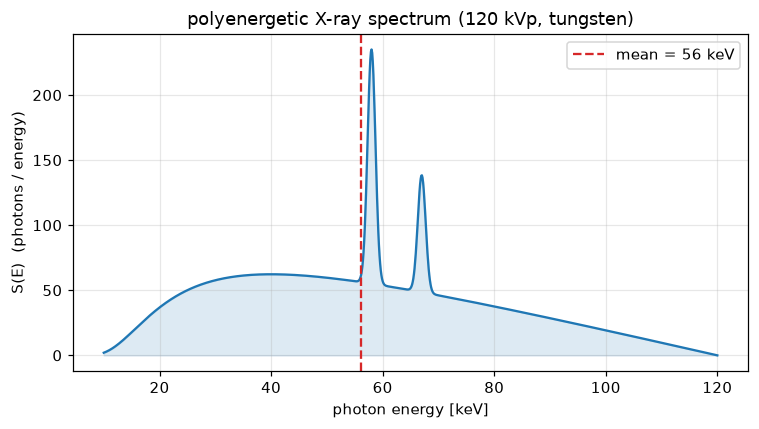

In [5]:
E = np.linspace(10, 120, 1000)                 # photon energy [keV], 120 kVp tube
kVp = 120.0

# Simple bremsstrahlung continuum (Kramers-like), zero above kVp, suppressed at low E by the window
brem = np.clip(kVp - E, 0, None) * np.exp(-((20.0 / E) ** 2))
# Tungsten characteristic K-lines (~58 and 67 keV), modeled as narrow Gaussians
char = 180 * np.exp(-((E - 58.0) / 1.0) ** 2) + 90 * np.exp(-((E - 67.0) / 1.0) ** 2)
S = brem + char

flux = np.trapezoid(S, E)
E_mean = np.trapezoid(E * S, E) / flux
print(f"photon flux (area under spectrum) = {flux:.1f} (a.u.)")
print(f"mean photon energy E_bar          = {E_mean:.1f} keV")

plt.figure(figsize=(7, 4))
plt.plot(E, S, color="tab:blue")
plt.axvline(E_mean, color="tab:red", ls="--", label=f"mean = {E_mean:.0f} keV")
plt.fill_between(E, S, alpha=0.15, color="tab:blue")
plt.xlabel("photon energy [keV]"); plt.ylabel("S(E)  (photons / energy)")
plt.title("polyenergetic X-ray spectrum (120 kVp, tungsten)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 4. Beam hardening

**Soft** X-rays = lower energy; **hard** X-rays = higher energy. Adding **filtration** (e.g. an Al or
Cu filter) preferentially removes **low-energy** photons. The surviving beam has a **higher mean
energy** — it is “harder.” This lowers patient dose (soft photons that would be absorbed in skin are
removed) but reduces soft-tissue contrast.

mean energy before filtration = 56.2 keV
mean energy after  filtration = 64.3 keV  (beam 'hardened')


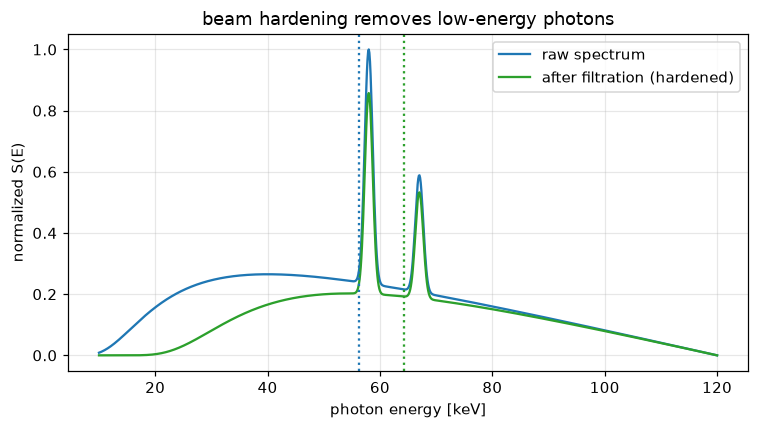

In [6]:
# Filter attenuates low energies more strongly: transmission T(E) = exp(-a / E^3)
a = 3.0e4
T = np.exp(-a / E**3)
S_hard = S * T

E_mean_hard = np.trapezoid(E * S_hard, E) / np.trapezoid(S_hard, E)
print(f"mean energy before filtration = {E_mean:.1f} keV")
print(f"mean energy after  filtration = {E_mean_hard:.1f} keV  (beam 'hardened')")

plt.figure(figsize=(7, 4))
plt.plot(E, S / S.max(), label="raw spectrum", color="tab:blue")
plt.plot(E, S_hard / S.max(), label="after filtration (hardened)", color="tab:green")
plt.axvline(E_mean, color="tab:blue", ls=":"); plt.axvline(E_mean_hard, color="tab:green", ls=":")
plt.xlabel("photon energy [keV]"); plt.ylabel("normalized S(E)")
plt.title("beam hardening removes low-energy photons")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 5. Ionization: photoelectric effect vs Compton scattering

Diagnostic X-rays are **ionizing** (the threshold is ~13.6 eV; diagnostic beams are **12–124 keV**,
far above it; gamma rays used in nuclear imaging are MeV-scale). Two dominant interactions:

- **Photoelectric effect** — a photon ejects a bound electron. Probability rises steeply with the
  **effective atomic number** $Z_\text{eff}$ (roughly $\propto Z^3$) and falls with energy
  (roughly $\propto 1/E^3$). This is what makes **bone** (high-$Z$ calcium) so conspicuous at low kVp.
- **Compton scattering** — a photon scatters off a loosely bound electron. Probability tracks
  **electron density** (nearly tissue-independent) and dominates at higher energies.

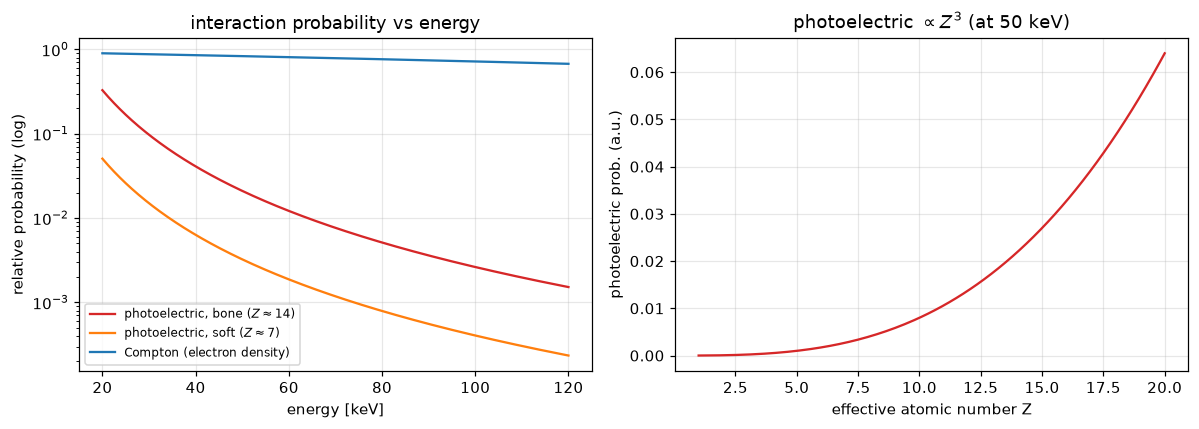

In [7]:
E2 = np.linspace(20, 120, 400)        # keV

# Illustrative scaling laws (relative, not absolute cross-sections)
def photoelectric(E, Z):
    return (Z ** 3) / (E ** 3)

def compton(E):
    return 0.9 * np.ones_like(E) * (1.0 - 0.0025 * (E - 20))  # weak, slow fall-off

pe_bone = photoelectric(E2, Z=13.8)   # ~Z_eff of bone
pe_soft = photoelectric(E2, Z=7.4)    # ~Z_eff of soft tissue
cs = compton(E2)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(E2, pe_bone, label="photoelectric, bone ($Z\\approx14$)", color="tab:red")
ax[0].semilogy(E2, pe_soft, label="photoelectric, soft ($Z\\approx7$)", color="tab:orange")
ax[0].semilogy(E2, cs, label="Compton (electron density)", color="tab:blue")
ax[0].set_xlabel("energy [keV]"); ax[0].set_ylabel("relative probability (log)")
ax[0].set_title("interaction probability vs energy"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

# Photoelectric probability vs atomic number at fixed energy
Z = np.linspace(1, 20, 200)
ax[1].plot(Z, photoelectric(E=50.0, Z=Z), color="tab:red")
ax[1].set_xlabel("effective atomic number Z"); ax[1].set_ylabel("photoelectric prob. (a.u.)")
ax[1].set_title(r"photoelectric $\propto Z^3$ (at 50 keV)"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. Energy dependence of $\mu$ — soft/hard tissue separability

Because $\mu$ depends on energy, the **same bone** has a *lower* $\mu$ at high energy (less stopping)
than at low energy. At **low energy** the gap between $\mu_\text{bone}$ and $\mu_\text{soft}$ is large
— excellent **separability** (soft tissue visible: the “white mouse”). At **high energy** both
attenuations collapse toward each other and soft tissue nearly vanishes (only bone remains: the
“bony mouse”).

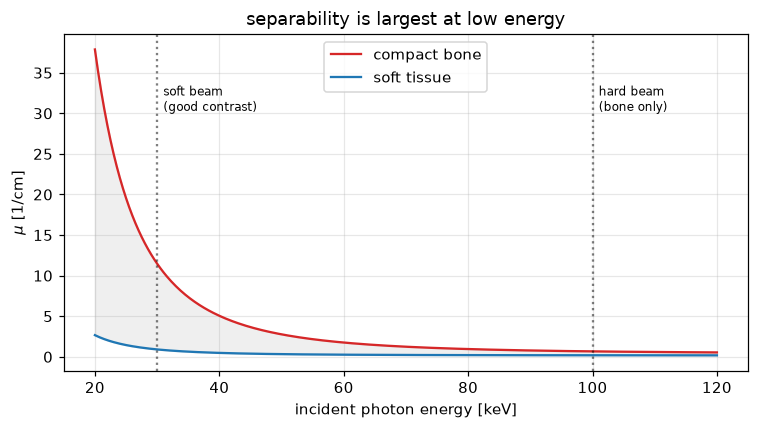

In [8]:
E3 = np.linspace(20, 120, 400)
mu_bone = 0.2 + 3.0e5 / E3**3 + 0.17     # strong photoelectric term -> steep low-E rise
mu_soft = 0.17 + 2.0e4 / E3**3           # weak photoelectric term

plt.figure(figsize=(7, 4))
plt.plot(E3, mu_bone, label="compact bone", color="tab:red")
plt.plot(E3, mu_soft, label="soft tissue", color="tab:blue")
plt.fill_between(E3, mu_soft, mu_bone, alpha=0.12, color="tab:gray")
for e, name in [(30, "soft beam\n(good contrast)"), (100, "hard beam\n(bone only)")]:
    plt.axvline(e, color="k", ls=":", alpha=0.5)
    plt.text(e + 1, mu_bone.max() * 0.8, name, fontsize=8)
plt.xlabel("incident photon energy [keV]"); plt.ylabel(r"$\mu$ [1/cm]")
plt.title("separability is largest at low energy")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 7. Half-value layer (HVL)

The **half-value layer** is the material thickness that transmits exactly **one half** of the
incident photons. From $\tfrac{1}{2} = e^{-\mu\,\text{HVL}}$:
$$\boxed{\;\text{HVL} = \dfrac{\ln 2}{\mu} = \dfrac{0.693}{\mu}\;}$$
HVL is **energy-specific** (because $\mu$ is) and is a convenient way to describe beam penetration
and shielding.

fat             mu = 0.190 /cm   HVL = 3.65 cm
water           mu = 0.214 /cm   HVL = 3.24 cm
compact bone    mu = 0.570 /cm   HVL = 1.22 cm
aluminium       mu = 0.620 /cm   HVL = 1.12 cm


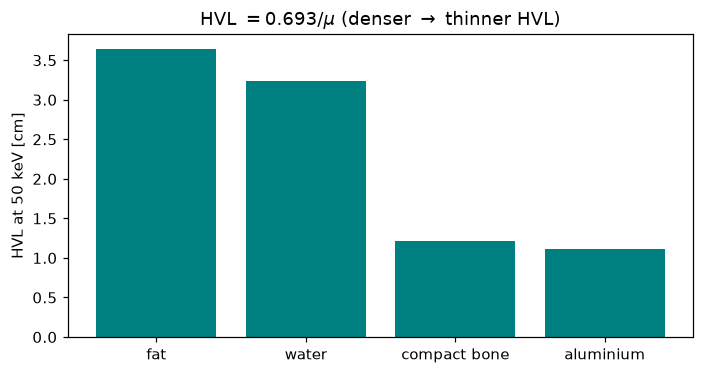

In [10]:
materials = ["fat", "water", "compact bone", "aluminium"]
mu_50keV = np.array([0.19, 0.214, 0.57, 0.62])    # approx linear attenuation at 50 keV [1/cm]
hvl = 0.693 / mu_50keV                              # [cm]
for m, u, h in zip(materials, mu_50keV, hvl):
    print(f"{m:14s}  mu = {u:.3f} /cm   HVL = {h:.2f} cm")

plt.figure(figsize=(6.5, 3.5))
plt.bar(materials, hvl, color="teal")
plt.ylabel("HVL at 50 keV [cm]"); plt.title(r"HVL $=0.693/\mu$ (denser $\to$ thinner HVL)")
plt.tight_layout(); plt.show()

## 8. Linear vs mass attenuation coefficient

As tissue **density** $\rho$ rises, electrons-per-unit-volume (**electron density**) rises, so $\mu$
rises. To remove the pure density effect we use the **mass attenuation coefficient**:
$$\frac{\mu}{\rho}\quad\left[\text{cm}^2/\text{g}\right].$$
A CT voxel value is ultimately rooted in the **linear attenuation coefficient** $\mu$ (cm$^{-1}$);
$\mu/\rho$ isolates the material’s intrinsic interaction probability from its packing density
(note how water and ice share nearly the same $\mu/\rho$).

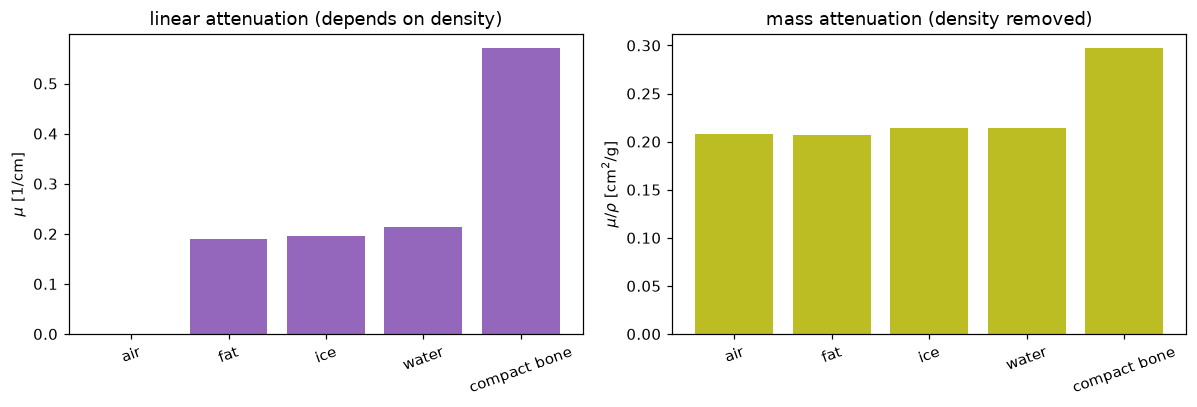

In [11]:
mats = ["air", "fat", "ice", "water", "compact bone"]
rho = np.array([0.0012, 0.92, 0.917, 1.00, 1.92])    # density [g/cm^3]
mu_lin = np.array([0.00025, 0.19, 0.196, 0.214, 0.57])  # linear attenuation at ~50 keV [1/cm]
mu_mass = mu_lin / rho                                 # mass attenuation [cm^2/g]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(mats, mu_lin, color="tab:purple"); ax[0].set_ylabel(r"$\mu$ [1/cm]")
ax[0].set_title("linear attenuation (depends on density)"); ax[0].tick_params(axis="x", rotation=20)
ax[1].bar(mats, mu_mass, color="tab:olive"); ax[1].set_ylabel(r"$\mu/\rho$ [cm$^2$/g]")
ax[1].set_title("mass attenuation (density removed)"); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## 9. Hounsfield units (CT number), bright/dark & contrast agents

CT voxel values are standardized as **Hounsfield units (HU)**, normalizing $\mu$ (referenced near
**50 keV**) to water:
$$\text{HU} = 1000\;\frac{\mu - \mu_\text{water}}{\mu_\text{water}}.$$
By definition **water = 0 HU** and **air ≈ −1000 HU**; fat is negative, soft tissue slightly
positive, and dense bone strongly positive.

**Bright vs dark (radiograph).** *Bright* = high stopping power (high $\mu$) → little energy reaches
the film. *Dark* = low attenuation → the film is strongly exposed/“burnt.”

**Contrast agents.** Injecting a high-$Z$ agent (e.g. **iodine**) artificially raises $\mu$ along the
path, brightening vessels/lesions — the CT analogue of gadolinium in MRI.

tissue           mu [1/cm]        HU
air                 0.0003      -999
lung                0.0500      -766
fat                 0.1900      -112
water               0.2140         0
soft tissue         0.2250        51
compact bone        0.5700      1664
iodine blood        0.9500      3439


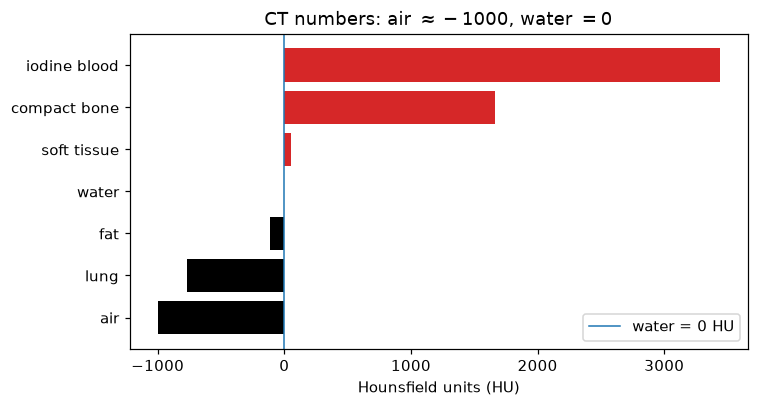

In [12]:
mu_water = 0.214                     # [1/cm] near 50 keV
tissue = {
    "air":          0.00025,
    "lung":         0.05,
    "fat":          0.19,
    "water":        0.214,
    "soft tissue":  0.225,
    "compact bone": 0.57,
    "iodine blood": 0.95,            # vessel after iodine contrast
}
print(f"{'tissue':14s}{'mu [1/cm]':>12s}{'HU':>10s}")
hu = {}
for name, m in tissue.items():
    hu[name] = 1000 * (m - mu_water) / mu_water
    print(f"{name:14s}{m:12.4f}{hu[name]:10.0f}")

plt.figure(figsize=(7, 3.8))
names = list(hu.keys()); vals = list(hu.values())
colors = ["k" if v < 0 else "tab:red" for v in vals]
plt.barh(names, vals, color=colors)
plt.axvline(0, color="tab:blue", lw=1, label="water = 0 HU")
plt.xlabel("Hounsfield units (HU)"); plt.title("CT numbers: air $\\approx-1000$, water $=0$")
plt.legend(); plt.tight_layout(); plt.show()

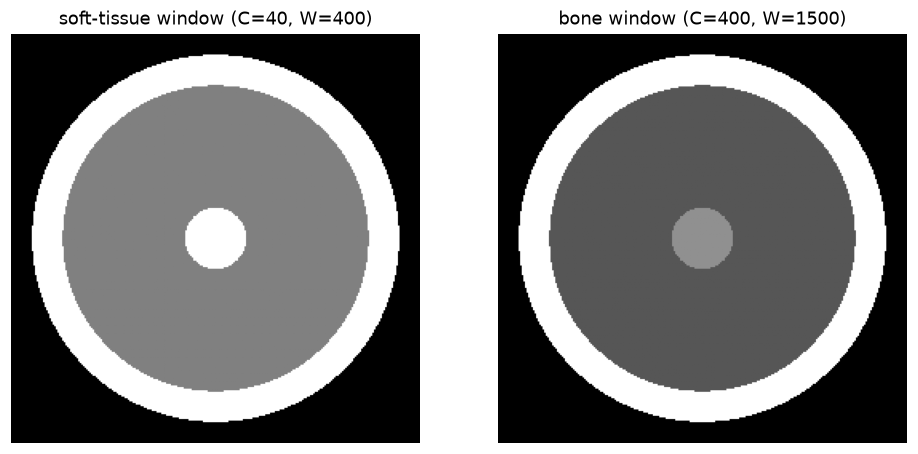

In [13]:
# Windowing: the same HU volume looks completely different under 'bone' vs 'soft-tissue' windows.
yy, xx = np.mgrid[-1:1:256j, -1:1:256j]
r = np.sqrt(xx**2 + yy**2)
ct = np.full_like(r, -1000.0)                      # background air
ct[r < 0.9] = 40                                    # soft tissue
ct[(r > 0.75) & (r < 0.9)] = 800                    # bony rim
ct[r < 0.15] = 300                                  # iodine-enhanced vessel

def window(img, center, width):
    lo, hi = center - width / 2, center + width / 2
    return np.clip((img - lo) / (hi - lo), 0, 1)

fig, ax = plt.subplots(1, 2, figsize=(9, 4.2))
ax[0].imshow(window(ct, center=40, width=400), cmap="gray")
ax[0].set_title("soft-tissue window (C=40, W=400)"); ax[0].axis("off")
ax[1].imshow(window(ct, center=400, width=1500), cmap="gray")
ax[1].set_title("bone window (C=400, W=1500)"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 10. Reconstruction preview & takeaways

From projections to a tomographic slice, we will study **three** reconstruction families:
1. **Radon / inverse Radon** — acquire projections at many angles, invert the transform (last lecture).
2. **Algebraic reconstruction (ART)** — set up and iteratively solve the linear system for the $\mu_i$
   along each ray (historically the EMI scanner / Hounsfield approach).
3. **Filtered back-projection (FBP)** — an image-domain method: filter each projection, then smear it
   back across the grid.

**Key takeaways**
- A radiograph is a **line integral of $\mu$**; CT inverts many such integrals into a cross-section.
- X-ray beams are **polyenergetic**: described by photon **flux** (area) and **mean energy**.
- **Photoelectric** ($\propto Z^3/E^3$) gives bone its low-energy conspicuity; **Compton** ($\propto$ electron density) dominates at high energy.
- **Beam hardening** raises mean energy, lowering dose but reducing soft-tissue contrast.
- $\text{HVL}=0.693/\mu$; **mass attenuation** $\mu/\rho$ removes the density effect.
- **Hounsfield units** reference $\mu$ to water (water 0, air −1000); **bright = high $\mu$**, and
  **iodine** contrast raises $\mu$ to highlight vessels.

*Next class:* CT-number ranges for tissues, the history of the **EMI scanner**, **algebraic
reconstruction**, and how **contrast agents** work.